In [1]:
from sklearn.datasets import make_classification
import numpy as np
X, y = make_classification(n_samples=100, n_features=2, n_informative=1,n_redundant=0,
                           n_classes=2, n_clusters_per_class=1, random_state=41,hypercube=False,class_sep=10)

In [2]:
import matplotlib.pyplot as plt

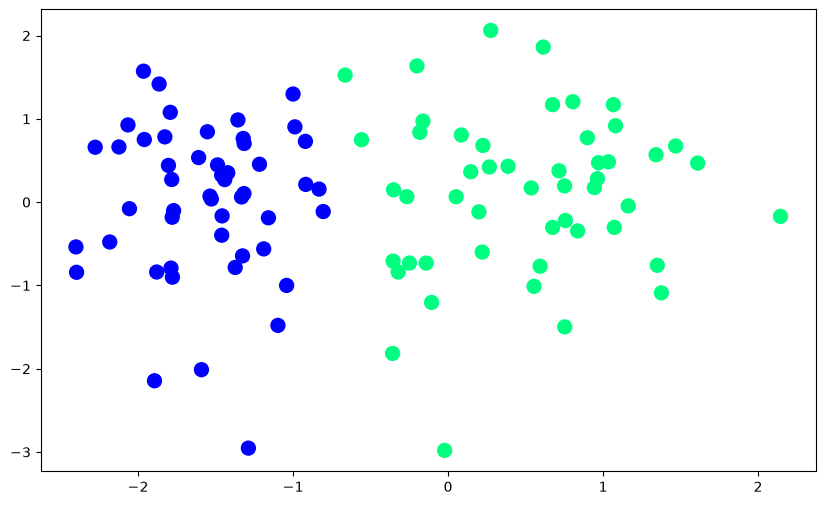

In [3]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

In [4]:
def perceptron(X,y):
    
    X = np.insert(X,0,1,axis=1)                          # It is for the bias term, we add a column of 1s to the input data.
    weights = np.ones(X.shape[1])
    lr = 0.1                                             # Learning rate
    
    for i in range(1000):                                # Training for 1000 iterations called epochs
        j = np.random.randint(0,100)                     # Randomly select a sample from the dataset
        y_hat = step(np.dot(X[j],weights))               # Predict the output using the step function
        weights = weights + lr*(y[j]-y_hat)*X[j]         # Update the weights using the perceptron learning rule. Formula: w = w + lr*(y-y_hat)*x
        
    return weights[0],weights[1:]                        # Return the bias term and the weights for the features
        

In [5]:
def step(z):
    return 1 if z>0 else 0

In [6]:
intercept_,coef_ = perceptron(X,y)

In [7]:
print(coef_)
print(intercept_)

[1.34234102 0.17708743]
1.0


In [8]:
m = -(coef_[0]/coef_[1])               # Slope of the decision boundary Formula: m = -w1/w2
b = -(intercept_/coef_[1])             # Y-intercept of the decision boundary Formula: b = -b/w2

In [9]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input + b

(-3.0, 2.0)

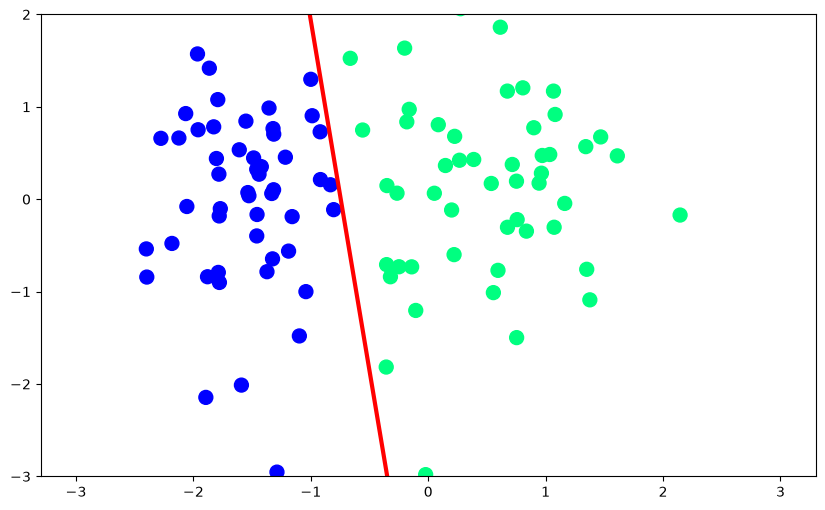

In [10]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)